In [13]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import re
import html

In [2]:
 #Download VADER lexicon if not already downloaded
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/twjcompute/nltk_data...


True

In [4]:
 #Step 3: Load the tweet data from a .txt file
# Replace 'tweets.txt' with your actual file path
with open('central_tweets/community_0_1Kmostcentral_2025-05-03.txt', 'r', encoding='utf-8') as file:
    tweets = [line.strip() for line in file if line.strip()]

In [5]:
# Create a DataFrame
tweets_df = pd.DataFrame({'text': tweets})

In [6]:
# Step 4: Display sample data to verify loading
print("Dataset shape:", tweets_df.shape)
print("\nSample tweets:")
print(tweets_df.head())

Dataset shape: (1857, 1)

Sample tweets:
                                                text
0  @funder Confirming what we already know... @se...
1  They only care about maintaining their own age...
2  Truly sad that even now they refuse to unite@f...
3                               @realDonaldTrump @VP
4                                    @CDCgov @HHSGov


In [ ]:
# Step 5: Optional - Create a deduplicated dataset
tweets_df_unique = tweets_df.drop_duplicates(subset=['text'])
print(f"\nTotal tweets: {len(tweets_df)}")
print(f"Unique tweets: {len(tweets_df_unique)}")
print(f"Duplicate percentage: {(1 - len(tweets_df_unique) / len(tweets_df)) * 100:.2f}%")


In [7]:
# Step 6: Initialize the VADER sentiment analyzer
sid = SentimentIntensityAnalyzer()

In [15]:
# Step 7: Define functions for Twitter-specific preprocessing and sentiment scoring

def twitter_preprocess(text_df):
    clean_list = []
    for text in text_df:
        # Decode HTML entities (like &amp; to &)
        text = html.unescape(text)

        # Remove URLs
        text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

        # Remove Twitter handles (@username)
        text = re.sub(r'@\w+', '', text)

        # Remove hashtag symbols but keep the text
        text = re.sub(r'#(\w+)', r'\1', text)

        # Remove RT prefix commonly found in retweets
        text = re.sub(r'^RT\s+', '', text)

        # Fix common encoding issues
        text = text.replace('&amp;', '&')
        text = text.replace('&lt;', '<')
        text = text.replace('&gt;', '>')

        # Remove extra whitespace
        text = re.sub(r'\s+', ' ', text).strip()
        
        clean_list.append(text)
    
    return pd.DataFrame({'text': clean_list})

In [16]:
# Twitter-specific preprocessing
clean_text = twitter_preprocess(tweets_df)
    
# For debugging, uncomment to see the preprocessing effect
# if text != clean_text:
#     print(f"Original: {text}\nCleaned: {clean_text}\n")

In [17]:
# Step 7: Define a function to get sentiment scores
def get_sentiment_scores(text):
    if pd.isna(text):  # Handle NaN values
        return None, None, None, None
    
    scores = sid.polarity_scores(text)
    return scores['neg'], scores['neu'], scores['pos'], scores['compound']

In [21]:
# Step 8: Apply sentiment analysis to both datasets
# For all tweets (including duplicates)
tweets_df['neg'], tweets_df['neu'], tweets_df['pos'], tweets_df['compound'] = zip(*tweets_df['text'].apply(get_sentiment_scores))
# Step 9: Analyze sentiment distribution
print("\nSentiment Distribution (All Tweets):")
print(tweets_df['compound'].describe())


Sentiment Distribution (All Tweets):
count    1857.000000
mean       -0.237763
std         0.468734
min        -0.999700
25%        -0.670500
50%         0.000000
75%         0.000000
max         0.988100
Name: compound, dtype: float64


In [ ]:
# For unique tweets only
tweets_df_unique['neg'], tweets_df_unique['neu'], tweets_df_unique['pos'], tweets_df_unique['compound'] = zip(*tweets_df_unique['text'].apply(get_sentiment_scores))
print("\nSentiment Distribution (Unique Tweets):")
print(tweets_df_unique['compound'].describe())

In [22]:
# Step 10: Categorize sentiment
def categorize_sentiment(compound_score):
    if compound_score >= 0.05:
        return 'Positive'
    elif compound_score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

In [23]:
# Apply categorization
tweets_df['sentiment'] = tweets_df['compound'].apply(categorize_sentiment)
#tweets_df_unique['sentiment'] = tweets_df_unique['compound'].apply(categorize_sentiment)

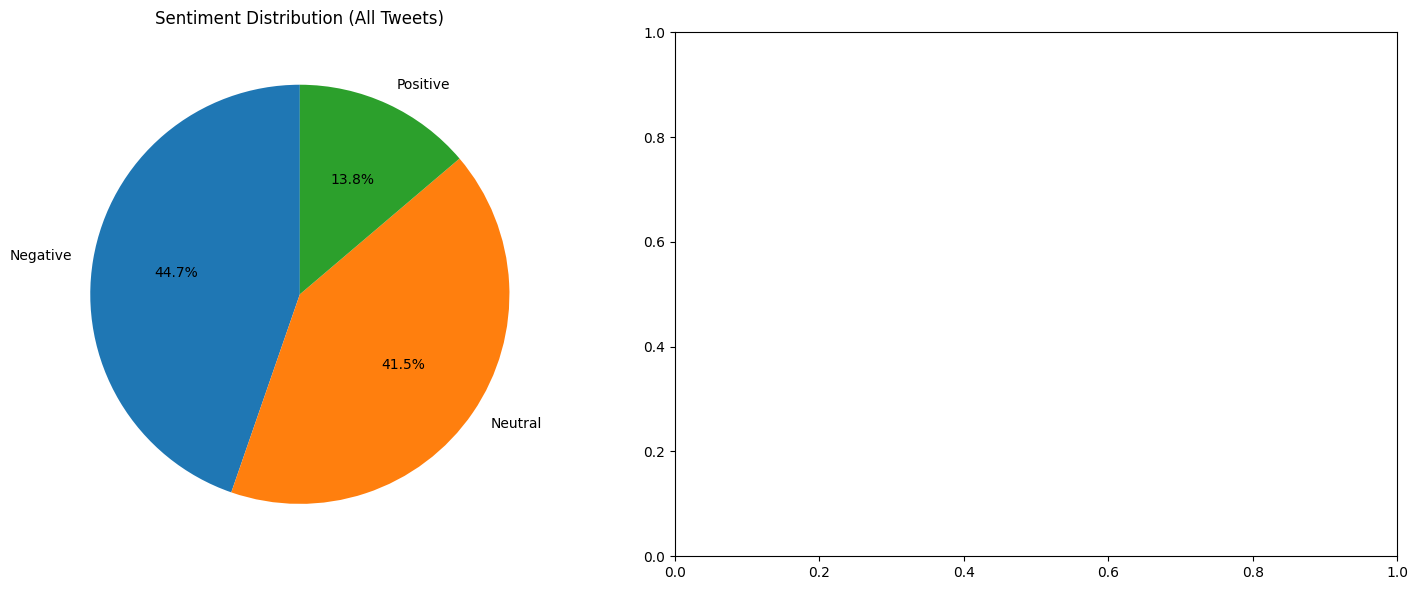

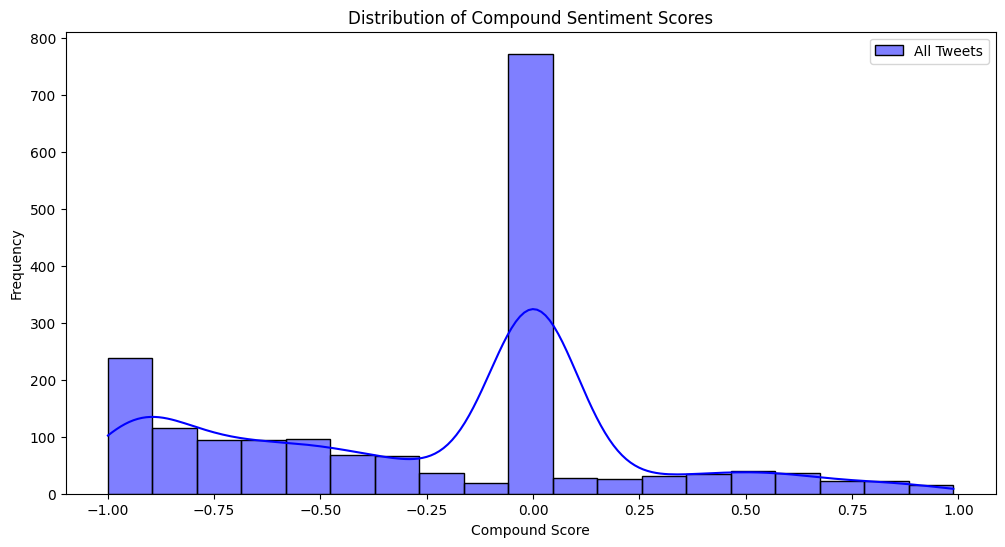

In [26]:
# Step 11: Compare sentiment distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
# All tweets sentiment
sentiment_counts = tweets_df['sentiment'].value_counts()
ax1.pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', startangle=90)
ax1.set_title('Sentiment Distribution (All Tweets)')
plt.tight_layout()
plt.show()
# Step 12: Visualize compound score distributions
plt.figure(figsize=(12, 6))
sns.histplot(data=tweets_df, x='compound', kde=True, color='blue', alpha=0.5, label='All Tweets')
#sns.histplot(data=tweets_df_unique, x='compound', kde=True, color='red', alpha=0.5, label='Unique Tweets')
plt.title('Distribution of Compound Sentiment Scores')
plt.xlabel('Compound Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [28]:
# Step 13: Optional - Save results to CSV
tweets_df.to_csv('vader_comunity_0.csv', index=False)
#tweets_df_unique.to_csv('unique_tweets_with_sentiment.csv', index=False)

In [38]:
# Step 14: Find example tweets for each sentiment category
print("\nExample Positive Tweet:")
print(tweets_df[tweets_df['sentiment'] == 'Positive']['text'].iloc[0])
print(sid.polarity_scores(tweets_df[tweets_df['sentiment'] == 'Positive']['text'].iloc[0]))

nltk.download('punkt_tab')
tokenized_sentence = nltk.word_tokenize(tweets_df[tweets_df['sentiment'] == 'Positive']['text'].iloc[0])

sid = SentimentIntensityAnalyzer()
pos_word_list=[]
neu_word_list=[]
neg_word_list=[]

for word in tokenized_sentence:
    if (sid.polarity_scores(word)['compound']) >= 0.1:
        pos_word_list.append(word)
    elif (sid.polarity_scores(word)['compound']) <= -0.1:
        neg_word_list.append(word)
    else:
        neu_word_list.append(word)                

print('Positive:',pos_word_list)        
print('Neutral:',neu_word_list)    
print('Negative:',neg_word_list) 
score = sid.polarity_scores(tweets_df[tweets_df['sentiment'] == 'Positive']['text'].iloc[0])
print('\nScores:', score)

print("\nExample Neutral Tweet:")
print(tweets_df[tweets_df['sentiment'] == 'Neutral']['text'].iloc[0])
print(sid.polarity_scores(tweets_df[tweets_df['sentiment'] == 'Neutral']['text'].iloc[0]))

print("\nExample Negative Tweet:")
print(tweets_df[tweets_df['sentiment'] == 'Negative']['text'].iloc[0])
print(sid.polarity_scores(tweets_df[tweets_df['sentiment'] == 'Negative']['text'].iloc[0]))


Example Positive Tweet:
@funder Confirming what we already know... @senatemajldr @realDonaldTrump and the rest of the @GOP don't give a damn about the American public or the #Coronavirus #CoronavirusPandemic
{'neg': 0.0, 'neu': 0.914, 'pos': 0.086, 'compound': 0.3089}
Positive: []
Neutral: ['@', 'funder', 'Confirming', 'what', 'we', 'already', 'know', '...', '@', 'senatemajldr', '@', 'realDonaldTrump', 'and', 'the', 'rest', 'of', 'the', '@', 'GOP', 'do', "n't", 'give', 'a', 'about', 'the', 'American', 'public', 'or', 'the', '#', 'Coronavirus', '#', 'CoronavirusPandemic']
Negative: ['damn']

Scores: {'neg': 0.0, 'neu': 0.914, 'pos': 0.086, 'compound': 0.3089}

Example Neutral Tweet:
@realDonaldTrump @VP
{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}

Example Negative Tweet:
Truly sad that even now they refuse to unite@funder I doubt @senatemajldr is immune to the coronavirus, and both trump and pence have been exposed to the virus… https://t.co/UB5IaPvs4r@funder @realDonaldTrump

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/twjcompute/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
